# Email Spam Detection Using Logistic Regression

Original analysis, cleaned and documented for publication. Fit a recipient-count model, investigate separation in a larger model, and compare classification thresholds. Saved results come from the original notebook.

All reported classification results are in-sample: the same 3,921 messages were used for fitting and evaluation. They do not measure performance on unseen email. Warnings and intermediate unstable models are intentionally retained to explain the analysis.

## Setup and data

Install `requirements.txt` in your Python environment, then launch Jupyter from this repository. Obtain an authorized copy of the original CSV and place it in `data/email.csv`. The dataset is omitted because redistribution permission has not been established. Raw-row previews have been removed from saved output; rerunning locally will display them.

In [ ]:
import pandas as pd

In [ ]:
from pathlib import Path

DATA_PATH = Path("data") / "email.csv"
if not DATA_PATH.is_file():
    raise FileNotFoundError(f"Place the authorized dataset at {DATA_PATH.resolve()}. See README.md.")

email = pd.read_csv(
    DATA_PATH
)

email.shape

(3921, 19)

In [ ]:
email.head()

## Single-predictor logistic model

In [ ]:
email['to_multiple_num'] = email['to_multiple'].map({
    'no': 0,
    'yes': 1
})

email[['spam', 'to_multiple', 'to_multiple_num']].head()

In [ ]:
import statsmodels.api as sm

model1 = sm.Logit(
    email['spam'],
    sm.add_constant(email['to_multiple_num'])
).fit()

print(model1.summary())

Optimization terminated successfully.
         Current function value: 0.302476
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:                   spam   No. Observations:                 3921
Model:                          Logit   Df Residuals:                     3919
Method:                           MLE   Df Model:                            1
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                 0.02674
Time:                        20:49:05   Log-Likelihood:                -1186.0
converged:                       True   LL-Null:                       -1218.6
Covariance Type:            nonrobust   LLR p-value:                 6.904e-16
                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const              -2.1161      0.056    -37.665      0.000      -2.226      -2.006
to_multiple_nu

In [ ]:
import numpy as np

# Single recipient: to_multiple_num = 0
log_odds = model1.params['const']

odds = np.exp(log_odds)
probability = odds / (1 + odds)

print("Odds:", odds)
print("Probability:", probability)
print("Percentage:", probability * 100)

Odds: 0.12050237610319049
Probability: 0.10754316873674623
Percentage: 10.754316873674624


In [ ]:
# Multiple recipients: to_multiple_num = 1
log_odds = (
    model1.params['const']
    + model1.params['to_multiple_num']
)

odds = np.exp(log_odds)
probability = odds / (1 + odds)

print("Odds:", odds)
print("Probability:", probability)
print("Percentage:", probability * 100)

Odds: 0.019736842105263164
Probability: 0.019354838709677424
Percentage: 1.9354838709677424


## Multiple predictors and separation

In [ ]:
X_all = email.drop(
    columns=['spam', 'to_multiple_num']
)

X_all = pd.get_dummies(
    X_all,
    drop_first=True,
    dtype=int
)

X_all.head()

In [ ]:
model2 = sm.Logit(
    email['spam'],
    sm.add_constant(X_all)
).fit(maxiter=200)

print(model2.summary())

         Current function value: 0.212760
         Iterations: 200
                           Logit Regression Results                           
Dep. Variable:                   spam   No. Observations:                 3921
Model:                          Logit   Df Residuals:                     3901
Method:                           MLE   Df Model:                           19
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.3154
Time:                        21:10:05   Log-Likelihood:                -834.23
converged:                      False   LL-Null:                       -1218.6
Covariance Type:            nonrobust   LLR p-value:                9.540e-151
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               17.8917   4325.206      0.004      0.997   -8459.356    8495.139
num_char             0.0303      0.024      1.

site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [ ]:
pd.crosstab(
    email['sent_email'],
    email['spam'],
    margins=True
)

spam,0,1,All
sent_email,,,
no,2464,367,2831
yes,1090,0,1090
All,3554,367,3921


## Investigating unstable predictors

In [ ]:
X_test = X_all.drop(columns=['sent_email_yes'])

model_test = sm.Logit(
    email['spam'],
    sm.add_constant(X_test)
).fit(maxiter=200)

print("Converged:", model_test.mle_retvals['converged'])

Optimization terminated successfully.
         Current function value: 0.230510
         Iterations 181
Converged: True


In [ ]:
print(model_test.summary())

                           Logit Regression Results                           
Dep. Variable:                   spam   No. Observations:                 3921
Model:                          Logit   Df Residuals:                     3902
Method:                           MLE   Df Model:                           18
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.2583
Time:                        21:24:31   Log-Likelihood:                -903.83
converged:                       True   LL-Null:                       -1218.6
Covariance Type:            nonrobust   LLR p-value:                4.906e-122
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               41.2844        nan        nan        nan         nan         nan
num_char             0.0452      0.023      1.995      0.046       0.001       0.090
line_breaks         -0.0050 

In [ ]:
pd.crosstab(
    email['from'],
    email['spam'],
    margins=True
)

spam,0,1,All
from,,,
no,0,3,3
yes,3554,364,3918
All,3554,367,3921


## Model after removing separating predictors

In [ ]:
X_fixed = X_all.drop(
    columns=['sent_email_yes', 'from_yes']
)

model_fixed = sm.Logit(
    email['spam'],
    sm.add_constant(X_fixed)
).fit(maxiter=200)

print(model_fixed.summary())

Optimization terminated successfully.
         Current function value: 0.231541
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                   spam   No. Observations:                 3921
Model:                          Logit   Df Residuals:                     3903
Method:                           MLE   Df Model:                           17
Date:                Mon, 26 Oct 2026   Pseudo R-squ.:                  0.2550
Time:                        21:28:23   Log-Likelihood:                -907.87
converged:                       True   LL-Null:                       -1218.6
Covariance Type:            nonrobust   LLR p-value:                4.098e-121
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -1.3675      0.213     -6.409      0.000      -1.786      -0.949
num_char   

In [ ]:
print("Simple model AIC:", model1.aic)
print("Full model AIC:", model_fixed.aic)

Simple model AIC: 2376.0193042129786
Full model AIC: 1851.7414392844607


## In-sample predictions and threshold comparison

In [ ]:
email['predicted_spam'] = model_fixed.predict(
    sm.add_constant(X_fixed)
)

email[['spam', 'predicted_spam']].head()

In [ ]:
import matplotlib.pyplot as plt

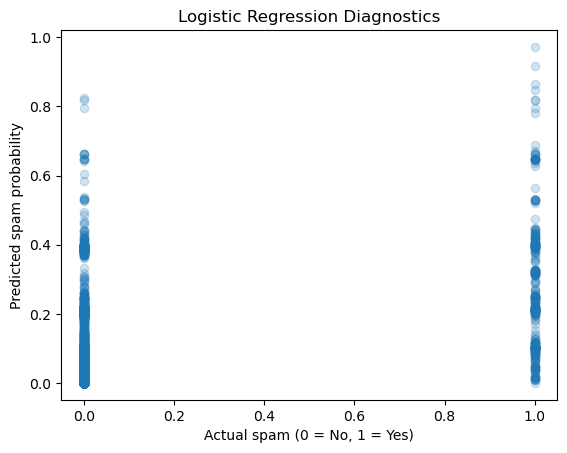

In [ ]:
plt.scatter(
    email['spam'],
    email['predicted_spam'],
    alpha=0.2
)

plt.xlabel("Actual spam (0 = No, 1 = Yes)")
plt.ylabel("Predicted spam probability")
plt.title("Logistic Regression Diagnostics")
plt.show()

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

email['predicted_class'] = (
    email['predicted_spam'] >= 0.5
).astype(int)

print(confusion_matrix(email['spam'], email['predicted_class']))
print(classification_report(email['spam'], email['predicted_class']))

[[3534   20]
 [ 329   38]]
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      3554
           1       0.66      0.10      0.18       367

    accuracy                           0.91      3921
   macro avg       0.79      0.55      0.57      3921
weighted avg       0.89      0.91      0.88      3921



In [ ]:
from sklearn.metrics import confusion_matrix, classification_report

predicted_30 = (email['predicted_spam'] >= 0.30).astype(int)

print(confusion_matrix(email['spam'], predicted_30))
print(classification_report(email['spam'], predicted_30))

[[3363  191]
 [ 224  143]]
              precision    recall  f1-score   support

           0       0.94      0.95      0.94      3554
           1       0.43      0.39      0.41       367

    accuracy                           0.89      3921
   macro avg       0.68      0.67      0.67      3921
weighted avg       0.89      0.89      0.89      3921



## Findings and limitations

The single-predictor model estimates spam probability at 10.75% for single-recipient messages and 1.94% for multiple-recipient messages. The full initial fit fails to converge; removing only `sent_email_yes` still leaves undefined standard errors. The final fit removes both `sent_email_yes` and `from_yes`, converges, and has AIC 1851.74 versus 2376.02 for the simple model.

At threshold 0.50, spam recall is about 10%; at 0.30 it is about 39%, with lower precision. Accuracy alone hides poor spam detection because the classes are imbalanced. A train/test split or cross-validation, training-only preprocessing, and threshold selection on validation data are needed before claiming predictive performance.